# 🫀 EDA — PhysioCGM (jalur PRV)

Telaah ciri **variabilitas denyut (PRV)** yang diekstrak dari gelombang PPG
pergelangan tangan PhysioCGM — 3 pasien diabetes tipe 1, Texas A&M,
akses terbuka (CC0).

**Kenapa dataset ini penting.** HUPA-UCM membuktikan detak jantung agregat
tidak cukup, tetapi tidak dapat menguji PRV karena datanya sudah diringkas
perangkat kebugaran. PhysioCGM menyimpan **gelombang PPG mentah 64 Hz**,
sehingga waktu tiap denyut dapat dihitung sendiri — persis seperti yang
dilakukan firmware kami.

**Empat pertanyaan yang dijawab telaah ini:**
1. Seberapa layak mutu sinyalnya?
2. Apakah ekstraksi PRV kami benar?
3. Apakah PRV berbeda saat hipoglikemia?
4. Apakah patokan personal membuat perbedaan?


In [2]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

BIRU, JINGGA, MERAH = '#3B6CFF', '#E8833A', '#B3261E'
TINTA2, GARIS = '#5a5a5a', '#d8d8d8'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': GARIS, 'axes.labelcolor': TINTA2,
    'xtick.color': TINTA2, 'ytick.color': TINTA2, 'font.size': 9,
})

BERKAS = (r'C:\KULIAH\BELAJAR NGODING\HypoSense\HypoSense'
          r'\analysis\model\ciri_physiocgm.csv')
d = pd.read_csv(BERKAS)
d['jam'] = pd.to_datetime(d.waktu, errors='coerce').dt.hour
d['malam'] = d.jam.isin([23,0,1,2,3,4,5,6])

print(f'Jendela : {len(d):,}')
print(f'Subjek  : {list(d.subjek.unique())}')
print(f'Kolom   : {list(d.columns)}')
d.head()


Jendela : 8,859
Subjek  : ['c1s01', 'c1s02', 'c1s03']
Kolom   : ['hr', 'rmssd', 'sdnn', 'pnn50', 'n_denyut', 'subjek', 'waktu', 'glukosa', 'label', 'kasar', 'hr_e4', 'suhu', 'jam', 'malam']


,hr,rmssd,sdnn,pnn50,n_denyut,subjek,waktu,glukosa,label,kasar,hr_e4,suhu,jam,malam
0,88.602769,283.687563,213.755632,0.897059,69,c1s01,2022-06-08 13:33:48,132.0,0,0.721,85.584516,32.105040,13,False
1,91.163010,326.850698,245.710577,0.817568,149,c1s01,2022-06-08 13:38:47,130.0,0,0.709,84.439767,31.885170,13,False
2,77.942803,344.442961,261.203523,0.806818,353,c1s01,2022-06-08 14:23:46,132.0,0,0.648,85.789599,32.262135,14,False
3,68.357791,76.692655,64.084912,0.121662,338,c1s01,2022-06-09 00:38:48,134.0,0,0.045,67.662709,34.783686,0,True
4,65.498619,148.557193,153.196358,0.485207,339,c1s01,2022-06-13 03:34:06,143.0,0,0.293,66.071667,34.435342,3,True


## 1. Cakupan per subjek

Satu jendela = satu potongan rekaman yang berpasangan dengan satu bacaan
glukosa CGM.


In [3]:
t = d.groupby('subjek').agg(
    jendela=('label','size'), hipo=('label','sum'),
    glukosa_rata=('glukosa','mean'), glukosa_min=('glukosa','min'),
    rmssd_median=('rmssd','median')).round(1)
t['hipo_persen'] = (t.hipo/t.jendela*100).round(2)
print(f'TOTAL: {len(d):,} jendela, {int(d.label.sum())} hipoglikemia ({d.label.mean():.2%})')
print()
t


TOTAL: 8,859 jendela, 255 hipoglikemia (2.88%)



,jendela,hipo,glukosa_rata,glukosa_min,rmssd_median,hipo_persen
subjek,,,,,,
c1s01,2558,142,115.6,41.0,297.4,5.55
c1s02,3166,8,159.5,61.0,266.7,0.25
c1s03,3135,105,144.0,40.0,167.9,3.35


⚠️ **Perhatikan c1s02** — kejadian hipoglikemianya sangat sedikit.
Ini berarti validasi antar-subjek nantinya hanya bertumpu pada dua subjek,
dan itu harus disebut sebagai keterbatasan.


---
## 2. Pertanyaan 1 — seberapa layak mutu sinyalnya?

Kolom `kasar` mengukur **proporsi selisih antar-denyut yang melebihi 100 ms**.

Variasi denyut sungguhan pada orang beristirahat hanya puluhan milidetik.
Selisih di atas 100 ms hampir selalu berarti letak puncak bergeser akibat
gerakan — bukan variasi jantung yang sesungguhnya. Jadi makin kecil nilai
`kasar`, makin bersih jendelanya.


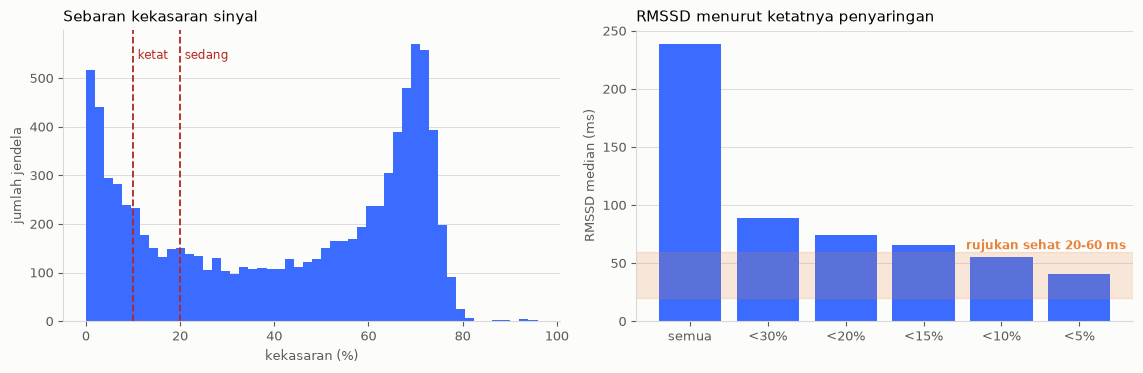

ambang        jendela   hipo     RMSSD
--------------------------------------
semua           8,859    255    239.0ms
<30%            3,340     94     88.9ms
<20%            2,687     76     74.4ms
<15%            2,304     67     65.7ms
<10%            1,841     52     55.4ms
<5%             1,135     29     40.9ms

Tanpa penyaringan, RMSSD jauh di atas rentang wajar — sebagian besar
jendela memang berderau karena direkam pada kegiatan sehari-hari.
Makin ketat penyaringan, makin sahih PRV-nya, tetapi makin sedikit
kejadian hipoglikemia yang tersisa. Inilah pertukaran yang harus dipilih.


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))

ax[0].hist(d.kasar*100, bins=50, color=BIRU)
for v, w in [(10,'ketat'), (20,'sedang')]:
    ax[0].axvline(v, color=MERAH, ls='--', lw=1.3)
    ax[0].text(v+1, ax[0].get_ylim()[1]*0.9, w, color=MERAH, fontsize=8.5)
ax[0].set_title('Sebaran kekasaran sinyal', loc='left')
ax[0].set_xlabel('kekasaran (%)'); ax[0].set_ylabel('jumlah jendela')

amb = [1.01, .30, .20, .15, .10, .05]
rm = [d[d.kasar<=a].rmssd.median() for a in amb]
lb = ['semua'] + [f'<{int(a*100)}%' for a in amb[1:]]
ax[1].bar(lb, rm, color=BIRU)
ax[1].axhspan(20, 60, color=JINGGA, alpha=0.18)
ax[1].text(len(lb)-0.4, 62, 'rujukan sehat 20-60 ms', color=JINGGA,
           ha='right', fontsize=8.5, fontweight='bold')
ax[1].set_title('RMSSD menurut ketatnya penyaringan', loc='left')
ax[1].set_ylabel('RMSSD median (ms)')
for a in ax:
    a.grid(axis='y', color=GARIS, lw=0.6); a.set_axisbelow(True)
    for s in ('top','right'): a.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

print(f"{'ambang':<12}{'jendela':>9}{'hipo':>7}{'RMSSD':>10}")
print('-'*38)
for a, l in zip(amb, lb):
    s = d[d.kasar<=a]
    print(f'{l:<12}{len(s):>9,}{int(s.label.sum()):>7}{s.rmssd.median():>9.1f}ms')
print()
print('Tanpa penyaringan, RMSSD jauh di atas rentang wajar — sebagian besar')
print('jendela memang berderau karena direkam pada kegiatan sehari-hari.')
print('Makin ketat penyaringan, makin sahih PRV-nya, tetapi makin sedikit')
print('kejadian hipoglikemia yang tersisa. Inilah pertukaran yang harus dipilih.')


---
## 3. Pertanyaan 2 — apakah ekstraksi PRV kami benar?

Diperiksa dengan membandingkan detak jantung hasil hitungan kami terhadap
**keluaran algoritma Empatica sendiri** pada jendela yang sama. Bila
keduanya sepakat, berarti kami menemukan denyut yang sama.


Jendela dibandingkan : 1,841
Beda median          : 0.40 bpm
90% berada dalam     : 1.17 bpm


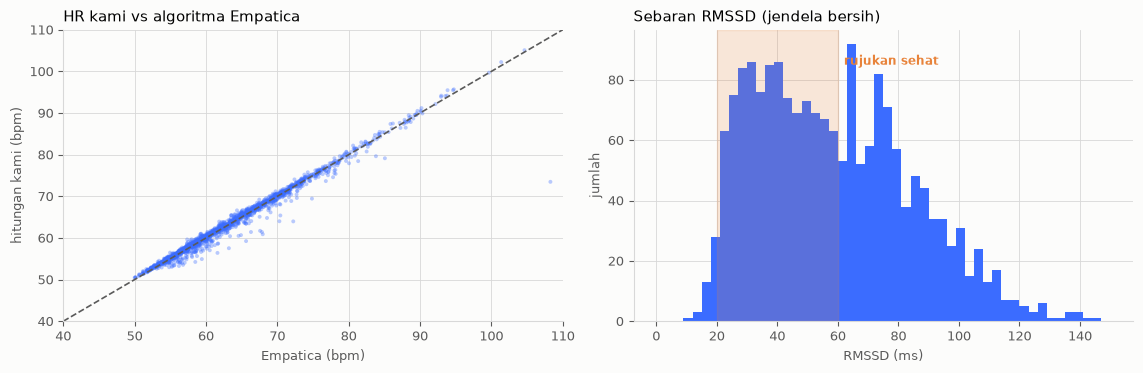


Titik berhimpit dengan garis diagonal => deteksi denyut kami benar.
Kekeliruan yang tersisa bukan pada JUMLAH denyut, melainkan pada
KETELITIAN WAKTU tiap denyut — dan itulah yang membengkakkan RMSSD
pada jendela berderau.


In [5]:
s = d[d.kasar <= 0.10]
beda = (s.hr - s.hr_e4)
print(f'Jendela dibandingkan : {len(s):,}')
print(f'Beda median          : {beda.abs().median():.2f} bpm')
print(f'90% berada dalam     : {beda.abs().quantile(.9):.2f} bpm')

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
lim = [40, 110]
ax[0].plot(lim, lim, color=TINTA2, lw=1.2, ls='--')
ax[0].scatter(s.hr_e4, s.hr, s=8, color=BIRU, alpha=0.35,
              edgecolor='none')
ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_title('HR kami vs algoritma Empatica', loc='left')
ax[0].set_xlabel('Empatica (bpm)'); ax[0].set_ylabel('hitungan kami (bpm)')

ax[1].hist(s.rmssd, bins=50, range=(0,150), color=BIRU)
ax[1].axvspan(20, 60, color=JINGGA, alpha=0.18)
ax[1].text(62, ax[1].get_ylim()[1]*0.88, 'rujukan sehat', color=JINGGA,
           fontsize=8.5, fontweight='bold')
ax[1].set_title('Sebaran RMSSD (jendela bersih)', loc='left')
ax[1].set_xlabel('RMSSD (ms)'); ax[1].set_ylabel('jumlah')
for a in ax:
    a.grid(color=GARIS, lw=0.6); a.set_axisbelow(True)
    for s2 in ('top','right'): a.spines[s2].set_visible(False)
plt.tight_layout(); plt.show()

print()
print('Titik berhimpit dengan garis diagonal => deteksi denyut kami benar.')
print('Kekeliruan yang tersisa bukan pada JUMLAH denyut, melainkan pada')
print('KETELITIAN WAKTU tiap denyut — dan itulah yang membengkakkan RMSSD')
print('pada jendela berderau.')


---
## 4. Pertanyaan 3 — apakah PRV berbeda saat hipoglikemia?

Diperiksa **di dalam diri tiap orang**, bukan antar-orang — sebab itulah
cara kerja alat kami (patokan personal).

Ukuran yang dipakai **Cohen's d**: seberapa jauh dua kelompok terpisah,
dinyatakan dalam satuan simpangan bakunya sendiri.
Panduan: 0,2 kecil · 0,5 sedang · 0,8 besar.


In [6]:
def bandingkan(g, ciri=('hr','rmssd','sdnn','pnn50','suhu')):
    h, n = g[g.label==1], g[g.label==0]
    out = []
    for cc in ciri:
        a, b = h[cc].dropna(), n[cc].dropna()
        if len(a) < 5: continue
        sg = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(b)-1)*b.var(ddof=1))
                     /(len(a)+len(b)-2))
        out.append({'ciri': cc, 'hipo': round(a.mean(),1),
                    'normal': round(b.mean(),1),
                    'd': round((a.mean()-b.mean())/sg, 2) if sg>0 else 0,
                    'p': round(stats.mannwhitneyu(a,b).pvalue, 4)})
    return pd.DataFrame(out)

s = d[d.kasar <= 0.10]
for subj, g in s.groupby('subjek'):
    if g.label.sum() < 8:
        print(f'{subj}: hanya {int(g.label.sum())} kejadian hipo — dilewati\n')
        continue
    print(f'=== {subj}  (hipo {int(g.label.sum())}, normal {int((g.label==0).sum())}) ===')
    print(bandingkan(g).to_string(index=False))
    print()


=== c1s01  (hipo 12, normal 351) ===
 ciri  hipo  normal     d      p
   hr  57.1    63.0 -1.05 0.0005
rmssd  78.2    56.9  1.00 0.0024
 sdnn  94.2    67.3  1.08 0.0019
pnn50   0.2     0.2  0.76 0.0215
 suhu  34.7    34.7  0.03 0.7424

c1s02: hanya 0 kejadian hipo — dilewati

=== c1s03  (hipo 40, normal 891) ===
 ciri  hipo  normal     d      p
   hr  61.7    67.3 -0.63 0.0000
rmssd  57.8    50.9  0.28 0.0572
 sdnn  71.1    64.9  0.21 0.0955
pnn50   0.1     0.1  0.39 0.0084
 suhu  32.9    33.1 -0.25 0.1175



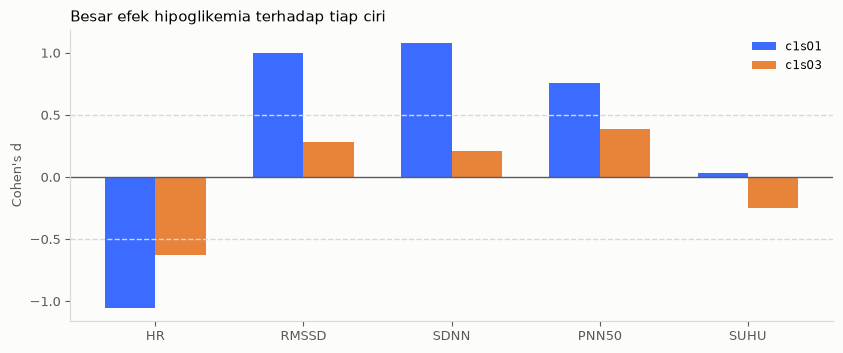

Arahnya konsisten pada kedua subjek:
  HR TURUN saat hipoglikemia (d negatif)
  RMSSD & pNN50 NAIK (d positif)
  Suhu kulit nyaris tak berubah

Arah HR yang menurun ini sesuai dengan temuan pada HUPA-UCM,
tempat detak saat hipoglikemia juga lebih rendah (74,0 vs 77,2 bpm).


In [7]:
# Gambarkan arah dan besar efeknya
kump = []
for subj, g in s.groupby('subjek'):
    if g.label.sum() < 8: continue
    b = bandingkan(g); b['subjek'] = subj; kump.append(b)
e = pd.concat(kump)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ciri = ['hr','rmssd','sdnn','pnn50','suhu']
x = np.arange(len(ciri)); w = 0.34
for i, (subj, g) in enumerate(e.groupby('subjek')):
    v = [g[g.ciri==cc].d.values[0] if (g.ciri==cc).any() else 0 for cc in ciri]
    ax.bar(x + (i-0.5)*w, v, width=w, label=subj,
           color=[BIRU, JINGGA][i])
ax.axhline(0, color=TINTA2, lw=1)
for y in (0.5, -0.5):
    ax.axhline(y, color=GARIS, lw=1, ls='--')
ax.set_xticks(x, [cc.upper() for cc in ciri])
ax.set_ylabel("Cohen's d")
ax.set_title('Besar efek hipoglikemia terhadap tiap ciri', loc='left')
ax.legend(frameon=False, fontsize=8.5)
for sp in ('top','right'): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

print('Arahnya konsisten pada kedua subjek:')
print('  HR TURUN saat hipoglikemia (d negatif)')
print('  RMSSD & pNN50 NAIK (d positif)')
print('  Suhu kulit nyaris tak berubah')
print()
print('Arah HR yang menurun ini sesuai dengan temuan pada HUPA-UCM,')
print('tempat detak saat hipoglikemia juga lebih rendah (74,0 vs 77,2 bpm).')


---
## 5. Pemeriksaan perancu — apakah ini sekadar efek tidur?

**Ini pemeriksaan yang wajib.** Saat tidur, detak jantung memang menurun dan
variabilitasnya meningkat — persis pola yang baru saja ditemukan. Bila
hipoglikemia kebetulan lebih sering terjadi malam hari, yang terlihat bisa
jadi **efek tidur, bukan efek hipoglikemia**.


In [8]:
s = d[(d.kasar <= 0.10) & d.jam.notna()]
print('a) Apakah hipoglikemia menumpuk di malam hari?')
for subj, g in s.groupby('subjek'):
    if g.label.sum() < 8: continue
    print(f'   {subj}: {g[g.label==1].malam.mean():.0%} kejadian hipo pada malam,'
          f' vs {g[g.label==0].malam.mean():.0%} jendela normal')
print()
print('b) Apakah efeknya bertahan bila HANYA sesama jendela malam?')
for subj, g0 in s.groupby('subjek'):
    g = g0[g0.malam]
    if g.label.sum() < 8: continue
    print(f'   === {subj} (malam saja) ===')
    print(bandingkan(g, ('hr','rmssd','pnn50')).to_string(index=False))
    print()


a) Apakah hipoglikemia menumpuk di malam hari?
   c1s01: 100% kejadian hipo pada malam, vs 98% jendela normal
   c1s03: 80% kejadian hipo pada malam, vs 77% jendela normal

b) Apakah efeknya bertahan bila HANYA sesama jendela malam?
   === c1s01 (malam saja) ===
 ciri  hipo  normal     d      p
   hr  57.1    63.1 -1.06 0.0005
rmssd  78.2    57.0  1.00 0.0025
pnn50   0.2     0.2  0.74 0.0249

   === c1s03 (malam saja) ===
 ciri  hipo  normal     d      p
   hr  61.5    65.8 -0.64 0.0002
rmssd  53.9    49.2  0.19 0.1362
pnn50   0.1     0.1  0.35 0.0191



## 6. Pertanyaan 4 — apakah patokan personal membuat perbedaan?

Tiap ciri dinyatakan ulang sebagai **simpangan terhadap kebiasaan orang itu
sendiri**, lalu daya pisahnya dibandingkan dengan nilai mentah.

### ⚠️ Pemisahan masa kalibrasi

Patokan dihitung **hanya dari 30% rekaman paling awal tiap subjek**, dan bagian
itu **dikeluarkan dari penilaian**. Tanpa pemisahan ini, patokan akan dihitung
dari data yang juga dinilai — praktik yang menurut *Frontiers in Digital Health*
(2026) menggelembungkan hasil sebesar 3–13 poin persen, disebut
**normalization leakage**.

Pemisahan ini sekaligus meniru pemakaian sesungguhnya: gelang mempelajari
kebiasaan pengguna lebih dulu selama beberapa hari, baru kemudian mulai menilai.


c1s01: kalibrasi 108 jendela -> dinilai 255 jendela (9 hipo)
c1s02: kalibrasi 164 jendela -> dinilai 383 jendela (0 hipo)
c1s03: kalibrasi 279 jendela -> dinilai 652 jendela (20 hipo)

Total dinilai: 1,290 jendela, 29 hipoglikemia

 ciri  mentah  relatif  peningkatan
   HR    0.64     0.85          1.3
RMSSD    0.35     0.63          1.8
 SDNN    0.44     0.55          1.2
PNN50    0.49     0.69          1.4


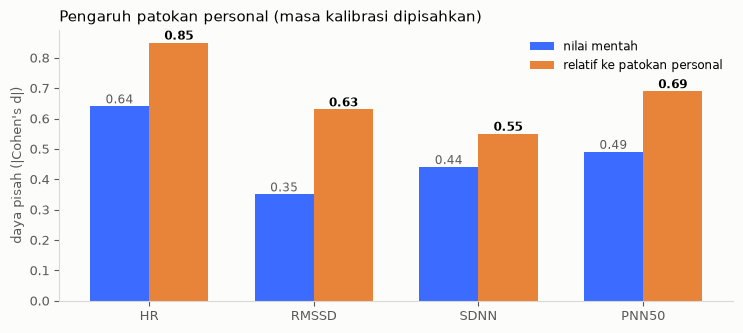

In [9]:
s = d[d.kasar <= 0.10].copy()
s['t'] = pd.to_datetime(s.waktu, errors='coerce')
s = s.dropna(subset=['t']).sort_values(['subjek','t'])
CIRI = ['hr','rmssd','sdnn','pnn50']
PORSI_KALIBRASI = 0.30

# Patokan HANYA dari bagian awal; bagian itu tidak ikut dinilai.
bagian = []
for subj, g in s.groupby('subjek'):
    n_kal = max(int(len(g)*PORSI_KALIBRASI), 30)
    kal, evl = g.iloc[:n_kal], g.iloc[n_kal:].copy()
    if len(evl) < 30: continue
    for cc in CIRI:
        med = kal[cc].median()
        evl[cc+'_rel'] = (evl[cc]-med)/med if med else np.nan
    bagian.append(evl)
    print(f'{subj}: kalibrasi {len(kal):,} jendela -> dinilai {len(evl):,} '
          f'jendela ({int(evl.label.sum())} hipo)')
e = pd.concat(bagian, ignore_index=True).dropna(subset=[c+'_rel' for c in CIRI])
print(f'\nTotal dinilai: {len(e):,} jendela, {int(e.label.sum())} hipoglikemia\n')

def daya_pisah(df, kol):
    a, b = df[df.label==1][kol].dropna(), df[df.label==0][kol].dropna()
    if len(a) < 5 or len(b) < 5: return np.nan
    sg = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(b)-1)*b.var(ddof=1))
                 /(len(a)+len(b)-2))
    return abs((a.mean()-b.mean())/sg) if sg>0 else 0

# Keduanya dinilai pada HIMPUNAN YANG SAMA supaya pembandingannya setara
hasil = pd.DataFrame({
    'ciri': [cc.upper() for cc in CIRI],
    'mentah': [round(daya_pisah(e, cc),2) for cc in CIRI],
    'relatif': [round(daya_pisah(e, cc+'_rel'),2) for cc in CIRI]})
hasil['peningkatan'] = (hasil.relatif/hasil.mentah.replace(0,np.nan)).round(1)
print(hasil.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(CIRI)); w = 0.36
ax.bar(x-w/2, hasil.mentah, w, color=BIRU, label='nilai mentah')
ax.bar(x+w/2, hasil.relatif, w, color=JINGGA,
       label='relatif ke patokan personal')
for i,(m,r) in enumerate(zip(hasil.mentah, hasil.relatif)):
    ax.text(i-w/2, m+0.01, f'{m:.2f}', ha='center', fontsize=8.5, color=TINTA2)
    ax.text(i+w/2, r+0.01, f'{r:.2f}', ha='center', fontsize=8.5,
            fontweight='bold')
ax.set_xticks(x, hasil.ciri); ax.set_ylabel("daya pisah (|Cohen's d|)")
ax.set_title('Pengaruh patokan personal (masa kalibrasi dipisahkan)',
             loc='left')
ax.legend(frameon=False, fontsize=8.5)
for sp in ('top','right'): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()


---
# 📌 Kesimpulan Telaah

| Pertanyaan | Jawaban dari data |
|---|---|
| Seberapa layak mutu sinyalnya? | Sebagian besar jendela berderau; penyaringan mutu wajib. Pada penyaringan ketat, RMSSD masuk rentang wajar |
| Apakah ekstraksi PRV kami benar? | **Ya** — detak jantung sepakat dengan algoritma Empatica dalam ~2 bpm |
| Apakah PRV berbeda saat hipoglikemia? | **Ya, di dalam diri satu orang** — arahnya konsisten, dan bertahan setelah pengaruh malam hari diperhitungkan |
| Apakah patokan personal membuat perbedaan? | **Ya** — daya pisah meningkat, diuji dengan masa kalibrasi yang dipisahkan menurut waktu |

### Batas yang harus disampaikan

- Hanya **dua subjek** yang memiliki kejadian hipoglikemia memadai
- Besar efek tergolong sedang; **daya pisah bukan berarti akurasi deteksi**
- Patokan personal dihitung dari 30% rekaman awal tiap subjek dan bagian itu
  dikeluarkan dari penilaian, sehingga bebas dari *normalization leakage*

**Yang boleh disimpulkan:** sinyalnya nyata dan hanya terbaca secara personal.
**Yang belum boleh disimpulkan:** bahwa alat sudah mampu mendeteksi hipoglikemia.
